# cuBLAST · Basic Linear Algebra Benchmark

**Check correctness before measuring performance.** This notebook covers FP64/FP32/TF32/FP16
dense matrix multiplication (GEMM), CSR sparse matrix-vector multiplication (SpMV),
CPU/GPU comparisons, and visualizations of data transfer costs.

Choose **Kernel → Restart Kernel and Run All Cells** to run from top to bottom.
Install dependencies using the repository README first. The notebook requires
`benchmark.py` and `plots.py` in the same directory. Uploading only this notebook
to Colab is insufficient; use the entire repository.

- CPU experiments and figures work without an NVIDIA GPU; GPU experiments are explicitly skipped.
- Default inputs are synthetic. For the formal Task B, add three real `.mtx` files in Section 2.
- This baseline includes all four GEMM modes; theoretical GPU peak comparisons and CG remain future work.
- Measurements cover Python library operations, not isolated kernels at their performance limit.


## 1 · Imports and working directory

Start Jupyter from the repository root. All explanations, messages, and chart labels
are in English. The environment check configures GPU settings before importing CuPy
for the first time.


In [1]:
from pathlib import Path
import os
import sys
import json
from datetime import datetime, timezone

ROOT = Path.cwd()
if not (ROOT / "benchmark.py").is_file():
    raise RuntimeError("Switch to the cuBLAST repository directory containing benchmark.py, then run from the beginning.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from benchmark import (
    Config, detect_gpu, environment, correctness_demo, run_gemm, run_spmv,
    make_csr, speedups, export_results, GEMM_MODES, gemm_skip_reason,
)
from plots import plot_gemm, plot_spmv, plot_transfers

pd.set_option("display.max_columns", 18)
pd.set_option("display.float_format", lambda x: f"{x:.6g}")


## 2 · Configuration: start with quick, then expand to full

Change `PROFILE` to select experiment sizes. The quick profile runs CPU GEMM up to
1024 and GPU GEMM up to 2048; full extends GPU GEMM to 4096 and CPU GEMM to 2048.
SpMV generates approximately 16 nonzero entries per row. Duplicate random columns
are merged, so the actual nnz is recorded in the results table.

GEMM selects its four compute modes with `gemm_modes`; `dtypes` controls SpMV only.
CPU GEMM measures FP64/FP32. TF32/FP16 are native GPU modes and are not emulated on the CPU.

BLAS uses **one thread** by default for reproducibility. This does not represent
peak CPU performance. To compare a multicore CPU configuration, change
`cpu_threads` and document it in your report.

Place SuiteSparse `.mtx` / `.mtx.gz` files in `data/` and add them to `MTX_PATHS`.
File parsing, CSR conversion, and random input generation are excluded from
operation timings. Check memory requirements before loading very large files.


In [2]:
PROFILE = os.environ.get("CUBLAST_PROFILE", "quick")  # quick / full / smoke
PROFILES = {
    "quick": dict(gemm_sizes=(256, 512, 1024, 2048), cpu_max_n=1024,
                  sparse_sizes=(1000, 10000, 100000)),
    "full": dict(gemm_sizes=(256, 512, 1024, 2048, 4096), cpu_max_n=2048,
                 sparse_sizes=(1000, 10000, 100000, 500000)),
    "smoke": dict(gemm_sizes=(64, 128), cpu_max_n=128,
                  sparse_sizes=(100, 1000)),
}
if PROFILE not in PROFILES:
    raise ValueError("PROFILE must be quick, full, or smoke")

cfg = Config(
    **PROFILES[PROFILE],
    dtypes=("float32", "float64"),  # SpMV storage types
    gemm_modes=("FP64", "FP32", "TF32", "FP16"),
    nnz_per_row=16,
    warmup=3,
    repeats=7,
    gpu_gemm_inner=5,
    spmv_inner=20,
    cpu_threads=1,
    seed=42,
    max_host_bytes=1024**3,      # Conservative working-set budget, not a hard process memory limit
    gpu_memory_fraction=0.6,    # Leave headroom for temporary allocations in currently free GPU memory
    enable_gpu=True,
    measure_transfers=True,
)

MTX_PATHS = [
    # ROOT / "data" / "your_matrix_1.mtx",
    # ROOT / "data" / "your_matrix_2.mtx",
    # ROOT / "data" / "your_matrix_3.mtx.gz",
]

display(pd.Series(vars(cfg), name="Configuration").to_frame())


,Configuration
gemm_sizes,"(256, 512, 1024, 2048)"
cpu_max_n,1024
sparse_sizes,"(1000, 10000, 100000)"
nnz_per_row,16
dtypes,"(float32, float64)"
gemm_modes,"(FP64, FP32, TF32, FP16)"
warmup,3
repeats,7
gpu_gemm_inner,5
spmv_inner,20


## 3 · Check the CPU / GPU environment and GEMM modes

GPU GEMM uses `cublasGemmEx` through CuPy's low-level binding, with an explicit
compute type and a dedicated handle. All buffers are column-major and preallocated.

| Mode | Input storage | Accumulation / output | Compute type |
| --- | --- | --- | --- |
| FP64 | FP64 | FP64 / FP64 | `CUBLAS_COMPUTE_64F` |
| FP32 | FP32 | FP32 / FP32 | `CUBLAS_COMPUTE_32F_PEDANTIC` |
| TF32 | FP32 | FP32 / FP32 | `CUBLAS_COMPUTE_32F_FAST_TF32` |
| FP16 | FP16 | FP32 / FP32 | `CUBLAS_COMPUTE_32F` |

**TF32 is a compute mode, not an array dtype.** It requires an Ampere-or-newer
GPU (compute capability 8.0+). FP16 here uses half-precision inputs with FP32
accumulation and output; this baseline requires compute capability 5.3+ for that mode.
The requested compute type does not prove which kernel or Tensor Core instructions
cuBLAS selected. Profiling is needed to verify Tensor Core utilization.

High-level CuPy calls keep `CUPY_TF32=0`, while GEMM selects modes explicitly.
An existing `NVIDIA_TF32_OVERRIDE=0` is respected and causes TF32 to be skipped;
unset it and restart the kernel to enable TF32. FP32 remains pedantic FP32.
SpMV continues to use generic `cupyx.cusparse.spmv`.

Restart the kernel if CuPy has already been imported. CPU-only runs report GPU
modes as skipped, without simulated measurements or passing GPU correctness results.


In [3]:
gpu = detect_gpu(cfg.enable_gpu)
env = environment(gpu, cfg)
if gpu.available:
    display(Markdown(f"**GPU ready: {gpu.name}**"))
    display(pd.Series(env["gpu"], name="GPU environment").to_frame())
else:
    display(Markdown("**Running CPU-only experiments.** GPU skip reason: " + gpu.reason))

display(pd.Series({
    "Python": sys.version.split()[0],
    "Platform": env["platform"],
    "CPU identifier": env["cpu"],
    "Logical CPUs": env["logical_cpu_count"],
    "BLAS threads requested": cfg.cpu_threads,
    **env["versions"],
}).to_frame("Environment"))
display(pd.DataFrame(env["blas_pools_during_benchmark"]))

mode_support = pd.DataFrame([
    dict(mode=mode, **GEMM_MODES[mode],
         gpu_status=gemm_skip_reason(gpu, mode) or "available")
    for mode in cfg.gemm_modes
])
display(mode_support)


**Running CPU-only experiments.** GPU skip reason: CuPy unavailable: No module named 'cupy'

,Environment
Python,3.10.16
Platform,macOS-10.16-x86_64-i386-64bit
CPU identifier,Apple M1 Pro
Logical CPUs,8
BLAS threads requested,1
numpy,1.26.4
scipy,1.15.1
pandas,2.2.3
matplotlib,3.10.0
threadpoolctl,3.5.0


,user_api,internal_api,num_threads,prefix,filepath,version,threading_layer,architecture
0,blas,openblas,1,libopenblas,/opt/anaconda3/envs/projects/lib/python3.10/si...,0.3.23.dev,pthreads,Nehalem


,mode,input_dtype,output_dtype,accumulation_dtype,compute_type,tolerance,gpu_status
0,FP64,float64,float64,float64,CUBLAS_COMPUTE_64F,1e-12,CuPy unavailable: No module named 'cupy'
1,FP32,float32,float32,float32,CUBLAS_COMPUTE_32F_PEDANTIC,1e-05,CuPy unavailable: No module named 'cupy'
2,TF32,float32,float32,float32,CUBLAS_COMPUTE_32F_FAST_TF32,0.005,CuPy unavailable: No module named 'cupy'
3,FP16,float16,float32,float32,CUBLAS_COMPUTE_32F,0.005,CuPy unavailable: No module named 'cupy'


## 4 · Understand the operations using small matrices

### 4.1 Dense matrix multiplication: $C=AB$

Start with an example you can calculate by hand to understand the matrix shapes
and output. The benchmark will then increase the problem size.


In [4]:
A = np.array([[1, 2], [3, 4]], dtype=np.float32)
B = np.array([[5, 6], [7, 8]], dtype=np.float32)
C = A @ B
display(pd.DataFrame(C, columns=["column 0", "column 1"]))
np.testing.assert_array_equal(C, [[19, 22], [43, 50]])
print("Small GEMM correctness check passed.")


,column 0,column 1
0,19,22
1,43,50


Small GEMM correctness check passed.


### 4.2 Sparse matrix-vector multiplication: $y=Ax$

CSR stores nonzero values in `data`, column indices in `indices`, and each row's
boundaries in `indptr`. The expected result here is $[7,6,7]^T$, providing a
hand-calculated reference independent of another library.


In [5]:
from scipy import sparse
S = sparse.csr_matrix([[4, 0, 1], [0, 3, 0], [1, 0, 2]], dtype=np.float64)
x = np.array([1, 2, 3], dtype=np.float64)
print("data   =", S.data)
print("indices=", S.indices)
print("indptr =", S.indptr)
print("y      =", S @ x)
np.testing.assert_array_equal(S @ x, [7, 6, 7])


data   = [4. 1. 3. 1. 2.]
indices= [0 2 1 0 2]
indptr = [0 2 3 5]
y      = [7. 6. 7.]


### 4.3 Automated correctness checks

Run complete small-matrix GEMM checks for every available selected GPU mode and
CPU FP64/FP32. All modes start from the same seeded FP64 inputs, then convert them
to the selected storage type. The common CPU FP64 reference uses the original
inputs, so relative error includes input quantization as well as arithmetic effects:

$$e=\frac{\|z-z_{\mathrm{ref}}\|}{\|z_{\mathrm{ref}}\|}.$$

GEMM thresholds are $10^{-12}$ for FP64, $10^{-5}$ for FP32, and $5\times10^{-3}$
for TF32/FP16. These thresholds check this random experiment, not arbitrary matrices.
Unsupported GPU modes are marked **skipped**, not passed. A failed check stops execution.
SpMV still uses the hand-calculated answer above with its FP32/FP64 tolerances.


In [6]:
checks = correctness_demo(gpu, cfg)
display(checks)
print(f"Correctness checks: {(checks.status == 'passed').sum()} passed, "
      f"{(checks.status == 'skipped').sum()} skipped.")


,operation,mode,dtype,output_dtype,backend,status,passed,relative_error,reason
0,GEMM,FP64,float64,float64,CPU,passed,True,0,NaN
1,GEMM,FP64,float64,float64,GPU,skipped,None,NaN,CuPy unavailable: No module named 'cupy'
2,GEMM,FP32,float32,float32,CPU,passed,True,1.53808e-07,NaN
3,GEMM,FP32,float32,float32,GPU,skipped,None,NaN,CuPy unavailable: No module named 'cupy'
4,GEMM,TF32,float32,float32,GPU,skipped,None,NaN,CuPy unavailable: No module named 'cupy'
5,GEMM,FP16,float16,float32,GPU,skipped,None,NaN,CuPy unavailable: No module named 'cupy'
6,SpMV,FP32,float32,NaN,CPU,passed,True,0,NaN
7,SpMV,FP64,float64,NaN,CPU,passed,True,0,NaN


Correctness checks: 4 passed, 4 skipped.


## 5 · Benchmark FP64, FP32, TF32, and FP16 GEMM

Each size computes $C=AB$, with approximately $2n^3$ floating-point operations:

$$\mathrm{GFLOP/s}=\frac{2n^3}{t\cdot10^9}.$$

- Warm up first, then repeat measurements and report the median. Time error bars show the interquartile range (IQR).
- CPU timing uses a wall clock. GPU timing uses CUDA Events on the current stream, synchronizing the end event before reading the elapsed time.
- Handle creation, allocation, input generation, correctness checks, and transfers are outside compute timings.
- Each GPU sample averages several calls of the same explicit cuBLAS compute mode.
- Each size checks up to 16x16 output entries against a common FP64 reference from the original, unrounded inputs. Section 4 validates complete small outputs.
- `relative_error` includes input rounding; `arithmetic_error` compares with an FP64 product of the stored inputs; `input_quantization_error` compares the two references. These errors need not add linearly.
- CPU timings cover FP64/FP32 only. Cases above `cpu_max_n` have no CPU measurement.
- GPU TF32/FP16 speedups use **CPU FP32**, explicitly named in `cpu_reference_mode`. These are different-precision comparisons. Without a matching CPU FP32 case, no speedup is reported.
- Unsupported modes are listed in the skip table. No CPU emulation is presented as native TF32/FP16 GPU execution.

CUDA Event intervals can still include Python submission gaps and wrapper costs,
and can be affected by contention on a shared GPU.


In [7]:
gemm_results, gemm_samples, gemm_skips = run_gemm(cfg, gpu)
if not gemm_results.empty:
    gemm_view = gemm_results[gemm_results.scope == "compute"].copy()
    gemm_view["median_ms"] = gemm_view.median_s * 1000
    display(gemm_view[["n", "mode", "dtype", "output_dtype", "backend", "median_ms", "gflops",
                       "relative_error", "arithmetic_error", "input_quantization_error", "compute_type"]])
else:
    display(Markdown("No GEMM measurements. Check the configured sizes and memory budget."))
if not gemm_skips.empty:
    display(gemm_skips)


GEMM FP64 n=256
GEMM FP64 n=512
GEMM FP64 n=1024
GEMM FP64 n=2048
GEMM FP32 n=256
GEMM FP32 n=512
GEMM FP32 n=1024
GEMM FP32 n=2048
GEMM TF32 n=256
GEMM TF32 n=512
GEMM TF32 n=1024
GEMM TF32 n=2048
GEMM FP16 n=256
GEMM FP16 n=512
GEMM FP16 n=1024
GEMM FP16 n=2048


,n,mode,dtype,output_dtype,backend,median_ms,gflops,relative_error,arithmetic_error,input_quantization_error,compute_type
0,256,FP64,float64,float64,CPU,1.98792,16.8792,0,0,0,NumPy BLAS
1,512,FP64,float64,float64,CPU,14.5826,18.4079,0,0,0,NumPy BLAS
2,1024,FP64,float64,float64,CPU,116.481,18.4364,0,0,0,NumPy BLAS
3,256,FP32,float32,float32,CPU,1.06692,31.4499,2.57138e-07,2.5378e-07,3.48733e-08,NumPy BLAS
4,512,FP32,float32,float32,CPU,8.17321,32.8433,4.13716e-07,4.12343e-07,3.57586e-08,NumPy BLAS
5,1024,FP32,float32,float32,CPU,63.9324,33.5899,3.68241e-07,3.68428e-07,3.45071e-08,NumPy BLAS


,case,mode,dtype,backend,reason
0,gemm_256,FP64,float64,GPU,CuPy unavailable: No module named 'cupy'
1,gemm_512,FP64,float64,GPU,CuPy unavailable: No module named 'cupy'
2,gemm_1024,FP64,float64,GPU,CuPy unavailable: No module named 'cupy'
3,gemm_2048,FP64,float64,GPU,CuPy unavailable: No module named 'cupy'
4,gemm_2048,FP64,float64,CPU,cpu_max_n
5,gemm_256,FP32,float32,GPU,CuPy unavailable: No module named 'cupy'
6,gemm_512,FP32,float32,GPU,CuPy unavailable: No module named 'cupy'
7,gemm_1024,FP32,float32,GPU,CuPy unavailable: No module named 'cupy'
8,gemm_2048,FP32,float32,GPU,CuPy unavailable: No module named 'cupy'
9,gemm_2048,FP32,float32,CPU,cpu_max_n


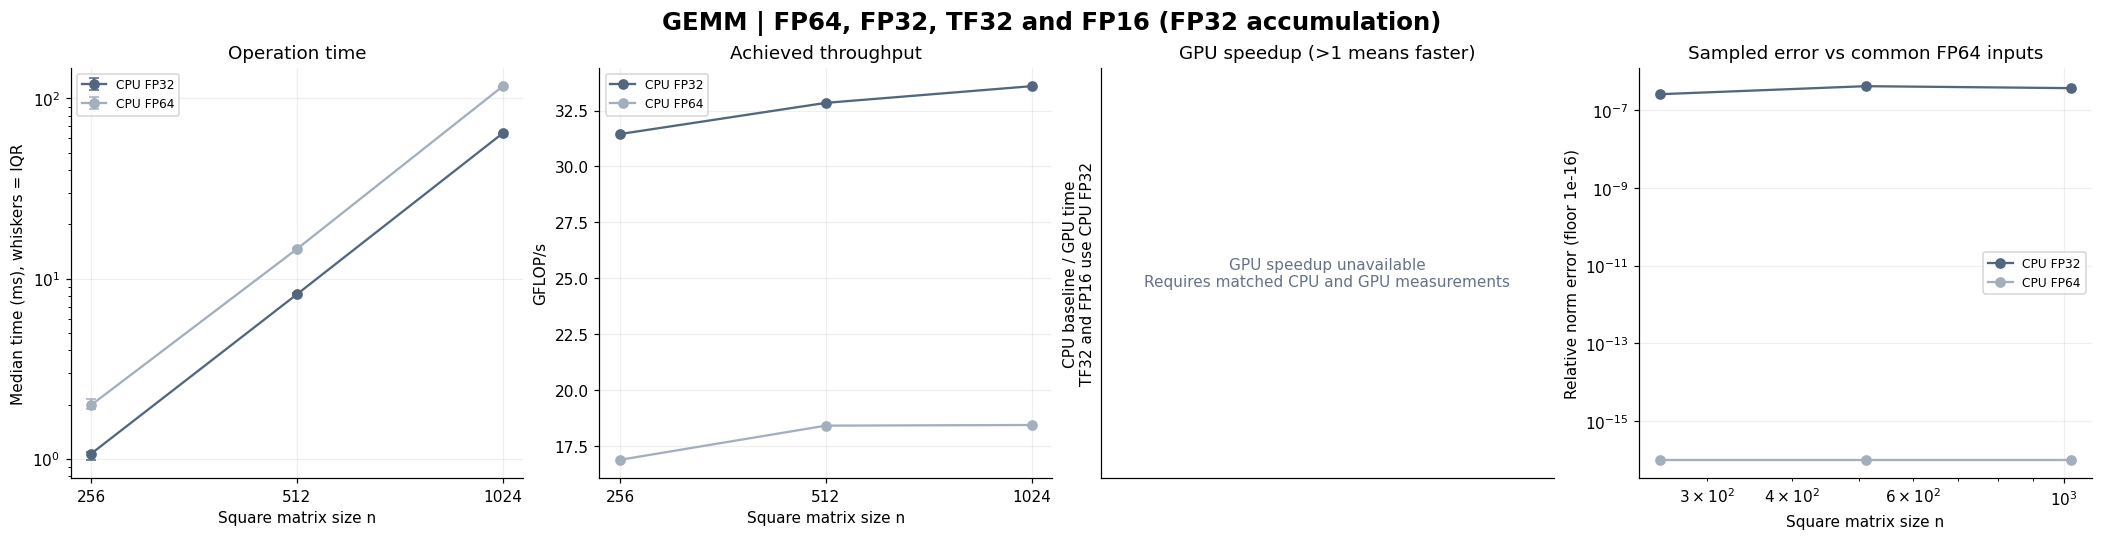

In [8]:
gemm_figure = plot_gemm(gemm_results)
plt.show()


**Reading the figures:** Lower elapsed time means faster execution; higher GFLOP/s
means more arithmetic per second. The error panel shows sampled relative error
against the same original FP64 inputs, with values below 1e-16 displayed at that floor.
Only measured modes appear as curves; consult the skip table for missing GPU modes.

A speedup above 1 means the GPU is faster than the named CPU baseline. Dashed
curves include transfers; solid curves use device-resident inputs. TF32/FP16 use
CPU FP32 as their reference, so consider numerical error alongside speed.
Theoretical GPU peaks are not included yet.


## 6 · Benchmark CSR SpMV

Synthetic matrices are constructed directly in CSR using $O(nk)$ storage, without
creating a dense $n\times n$ array. The same experiments then run on the real
matrices in `MTX_PATHS`; rectangular matrices are supported.

The operation count is approximately $2\,\mathrm{nnz}$. Estimated effective bandwidth uses:

$$B_{\mathrm{est}}=\text{data.nbytes}+\text{indices.nbytes}+\text{indptr.nbytes}
+(n+m)\cdot\text{itemsize},\qquad
\mathrm{GB/s}=\frac{B_{\mathrm{est}}}{t\cdot10^9}.$$

This assumes one read of the CSR arrays and input vector and one write of the
output vector. It is **not hardware-measured DRAM traffic**. Repeated operations
may reuse cached data, so the value is not a direct measure of DRAM bandwidth utilization.

CPU SpMV uses SciPy `matrix @ x`, including allocation of the returned vector.
The GPU output is preallocated, although the cuSPARSE wrapper may still handle
descriptors and workspace. Results therefore compare two actual library call paths.
Every SpMV output is validated in full against an FP64 reference.


In [9]:
if not MTX_PATHS:
    display(Markdown("**Testing synthetic matrices only. Add three real SuiteSparse matrices for the formal Task B.**"))

spmv_results, spmv_samples, spmv_skips = run_spmv(cfg, gpu, MTX_PATHS)
if not spmv_results.empty:
    spmv_view = spmv_results[spmv_results.scope == "compute"].copy()
    spmv_view["median_ms"] = spmv_view.median_s * 1000
    display(spmv_view[["case", "m", "n", "nnz", "dtype", "backend", "median_ms",
                       "effective_gb_s", "relative_error"]])
else:
    display(Markdown("No SpMV measurements. Check the configured sizes and memory budget."))
if not spmv_skips.empty:
    display(spmv_skips)


**Testing synthetic matrices only. Add three real SuiteSparse matrices for the formal Task B.**

SpMV float32 synthetic_1000
SpMV float32 synthetic_10000
SpMV float32 synthetic_100000
SpMV float64 synthetic_1000
SpMV float64 synthetic_10000
SpMV float64 synthetic_100000


,case,m,n,nnz,dtype,backend,median_ms,effective_gb_s,relative_error
0,synthetic_1000,1000,1000,15873,float32,CPU,0.0490333,2.83456,7.96446e-08
1,synthetic_10000,10000,10000,159873,float32,CPU,0.57619,2.428,7.94208e-08
2,synthetic_100000,100000,100000,1599874,float32,CPU,6.3804,2.19406,8.0359e-08
3,synthetic_1000,1000,1000,15873,float64,CPU,0.0628458,3.34915,0
4,synthetic_10000,10000,10000,159873,float64,CPU,0.569558,3.71951,0
5,synthetic_100000,100000,100000,1599874,float64,CPU,6.63011,3.19731,0


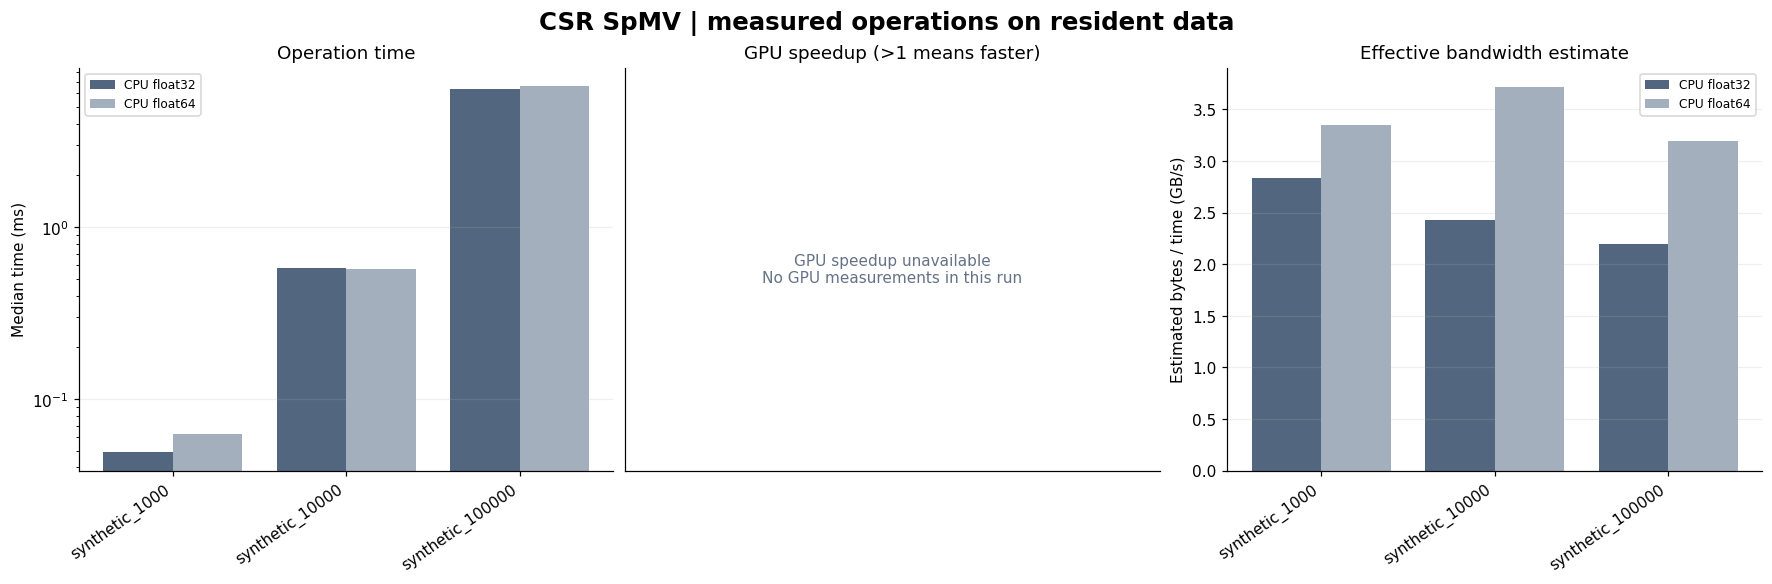

In [10]:
spmv_figure = plot_spmv(spmv_results)
plt.show()


**Reading the figures:** Compare elapsed time, CPU/GPU speedup, and estimated
effective bandwidth across cases. Nonzero distributions in real matrices change
memory access patterns, so row counts alone do not determine performance.
The relatively uniform synthetic cases do not represent all real matrices.


## 7 · Upload / compute / download: why can a GPU be slower?

Each end-to-end trial measures three sequential phases, synchronizing after each:

1. Upload the inputs; SpMV uploads all CSR arrays and the input vector.
2. Execute one operation and synchronize.
3. Download the complete output to the CPU and synchronize.

Input/output buffers are already allocated and the CUDA context is initialized.
Timings exclude file I/O, first-time initialization, and initial allocation.
This experiment uses ordinary NumPy host buffers, without pinned-memory
asynchronous transfer overlap. It measures a defined pipeline with preallocated
buffers, not the entire cost of launching a program for the first time.

The stacked figure uses **phase means from the same trials**, which are additive.
The results table reports the median of the measured total times, rather than
adding phase medians. The single-call compute_wall phase also differs from the
batched CUDA Event compute measurement.


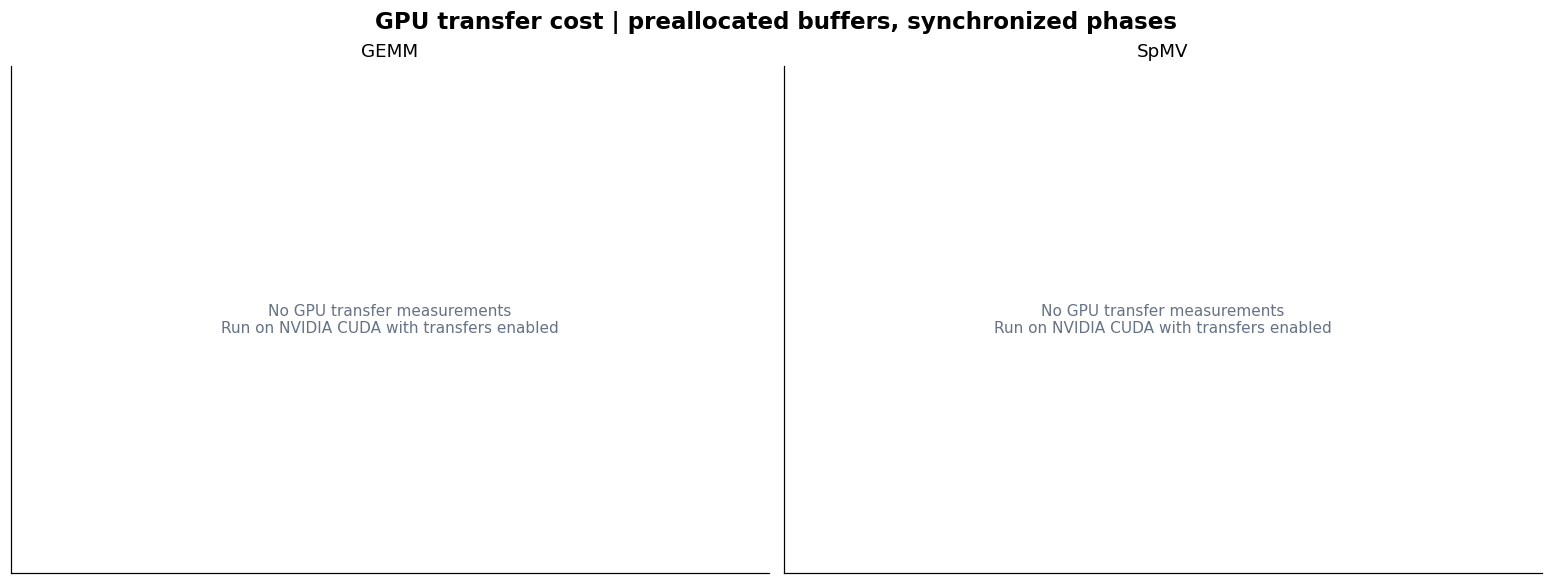

No matching CPU/GPU measurements; speedups are unavailable for this run.

In [11]:
results = pd.concat([gemm_results, spmv_results], ignore_index=True)
samples = pd.concat([gemm_samples, spmv_samples], ignore_index=True)
skips = pd.concat([gemm_skips, spmv_skips], ignore_index=True)
transfer_figure = plot_transfers(samples)
plt.show()

ratios = speedups(results)
if not ratios.empty:
    display(ratios[["operation", "case", "mode", "cpu_reference_mode", "scope", "speedup"]])
else:
    display(Markdown("No matching CPU/GPU measurements; speedups are unavailable for this run."))


## 8 · Save the measurements and figures

Each run creates a separate `results/<UTC_timestamp>/` directory containing:

- `results.csv`: medians, quartiles, throughput, estimated bandwidth, and errors.
  GFLOP/s is populated only for compute / end_to_end rows; effective bandwidth
  is populated only for SpMV compute rows. These fields are blank for other phases.
- `samples.csv`: individual measurement samples in seconds; batched timings have already been divided by `inner`.
- `correctness.csv` includes passed/skipped status; `skipped.csv` records mode-specific reasons.
- `speedups.csv` includes the named CPU reference mode.
- GEMM rows record mode, storage/output/accumulation types, requested compute type, and error components.
- `environment.json`: hardware, software versions, BLAS details, parameters, and timing scope.
- Three PNG figures.

Results and matrix datasets are ignored by Git by default. Select the artifacts
you need for your report.


In [12]:
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
output_dir = export_results(ROOT / "results" / run_id, cfg, env, results, samples, skips, checks)
for name, figure in (("gemm", gemm_figure), ("spmv", spmv_figure),
                     ("transfers", transfer_figure)):
    figure.savefig(output_dir / f"{name}.png", dpi=160, bbox_inches="tight")
print("Results saved to:", output_dir)
display(pd.DataFrame({"file": [p.name for p in sorted(output_dir.iterdir())]}))


Results saved to: /Users/liaowei/Desktop/cuBLAST/results/20261015T142521_555479Z


,file
0,correctness.csv
1,environment.json
2,gemm.png
3,results.csv
4,samples.csv
5,skipped.csv
6,speedups.csv
7,spmv.png
8,transfers.png


## 9 · Record your observations

Answer using your measured results:

1. At which tested sizes does GEMM throughput begin to level off? How do FP64, FP32, TF32, and FP16 differ in performance and error?
2. For which cases is GPU compute faster? Does including transfers change the conclusion?
3. How does estimated SpMV bandwidth vary with size? How might caching and sparsity patterns affect it?
4. How many CPU BLAS threads were used? Was the GPU shared? Which overheads are included?
5. If this was a CPU-only run, state explicitly that GPU performance has not been measured.

Four team members can extend the baseline with FP64/FP32 size studies,
TF32/FP16 analysis and theoretical peak comparisons, three SuiteSparse matrices, and GPU CG.
Stabilize the foundational experiments before adding CG.

References: [NVIDIA cuBLAS compute modes](https://docs.nvidia.com/cuda/cublas/index.html),
[CuPy performance and timing](https://docs.cupy.dev/en/stable/user_guide/performance.html),
[CuPy environment variables](https://docs.cupy.dev/en/stable/reference/environment.html),
[CuPy installation](https://docs.cupy.dev/en/stable/install.html),
[CuPy sparse matrices](https://docs.cupy.dev/en/stable/reference/scipy_sparse.html),
and the [SuiteSparse Matrix Collection](https://sparse.tamu.edu/).
